In [1]:
import numpy as np
import numpy.ma as ma
from netCDF4 import Dataset
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.colors
from matplotlib.colors import ListedColormap, LinearSegmentedColormap
import matplotlib.ticker as mticker
from matplotlib import colors

import matplotlib.gridspec as gridspec
import xarray as xr
from statsmodels.tsa.arima_model import ARMA
from statsmodels.tsa.arima_process import ArmaProcess
import string

import cartopy
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER
import cartopy.crs as ccrs
from scipy import signal
from scipy.signal import periodogram
import eofs
import iris
import iris.quickplot as qplt 
import iris.plot as iplt
iris.FUTURE.netcdf_promote=True
import iris.coord_categorisation

from iris.analysis import stats
from iris.analysis import maths
import glob

/apps/developers/compilers/canopy3/2.1.3/1/bit-64/Canopy/edm/envs/User/lib/python3.5/site-packages/matplotlib/ticker.py:1693: UserWarning: Steps argument should be a sequence of numbers
increasing from 1 to 10, inclusive. Behavior with
values outside this range is undefined, and will
raise a ValueError in future versions of mpl.
  warnings.warn('Steps argument should be a sequence of numbers\n'


### Open data

In [2]:
## Open AOU diff
path = '/nfs/hera1/ee22kvcs/PMIP4/'
models = [ 'ACCESS-ESM1-5', 'HadCM3', 'IPSL-CM6A-LR', 'KCM', 'MIROC-ES2L', 'NorESM1-F', 'NorESM2-LM']
names_models_dif = ['aou_diff_Oyr_ACCESS-ESM1-5_100ymean_regridded_360x385_intlevel.nc',
                   'aou_diff_Oyr_HadCM3_r1i1p1f1_6651-6750_regridded_385x360_ann_mean_intlevel.nc',
                   'aou_diff_Oyr_IPSL-CM6A-LR_r1i1p1f1_gn_1850-1949_regridded_360x385_100yr_mean_intlevel.nc',
                   'aou_diff_Oyr_KCM_r1i1p1f1_4901_5000_100yr_mean_intlevel.nc',
                   'aou_diff_Oyr_MIROC-ES2L_r1i1p1f2_gr1_330001-339912_regridded_360x385_100yr_mean_intlevel.nc',
                   'aou_diff_Oyr_NorESM1-F_r1i1p1f1_gr_1601-1700_100yr_mean_regridded_360x385_intlevel.nc',
                   'aou_diff_Oyr_NorESM2-LM_r1i1p1f1_gr_2101-2200_100yr_mean_regridded_360x385_intlevel.nc',]

constraints = [iris.Constraint(cube_func=lambda cube: cube.var_name == 'aou_diff'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'aou_diff'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'aou_diff'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'aou_diff'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'aou_diff'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'aou_diff'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'aou_diff')]

DIFF_models_aou = []
for i in range(np.size(models)):
    uploaded_cubes = iris.load_cube(path+names_models_dif[i], constraints[i])
    uploaded_cubes = iris.util.squeeze(uploaded_cubes)
    DIFF_models_aou.append(uploaded_cubes)

/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/_pyke_rules/compiled_krb/fc_rules_cf_fc.py:1813: FutureWarning: Conversion of the second argument of issubdtype from `str` to `str` is deprecated. In future, it will be treated as `np.str_ == np.dtype(str).type`.
  if np.issubdtype(cf_var.dtype, np.str):
/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/_pyke_rules/compiled_krb/fc_rules_cf_fc.py:1813: FutureWarning: Conversion of the second argument of issubdtype from `str` to `str` is deprecated. In future, it will be treated as `np.str_ == np.dtype(str).type`.
  if np.issubdtype(cf_var.dtype, np.str):
/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/_pyke_rules/compiled_krb/fc_rules_cf_fc.py:1813: FutureWarning: Conversion of the second argument of issubdtype from `str` to `str` is deprecated. In future, it will be treated as `np.str_ == np.dtype(str).type`.
  if np.issubdty

In [4]:
## Open masks
path_mask_atl = '/nfs/see-fs-01_users/mlzp121/Test_HadCM3_simulations/Mask_Atlantic_ocean_NorESM2-LM.nc'
path_mask_pac = '/nfs/see-fs-01_users/mlzp121/Test_HadCM3_simulations/Mask_Pacific_ocean_NorESM2-LM.nc'
path_mask_ind = '/nfs/see-fs-01_users/mlzp121/Test_HadCM3_simulations/Mask_Indian_ocean_NorESM2-LM.nc'

masks = iris.Constraint(cube_func=lambda cube: cube.var_name == 'mask')
# Open
atlantic_mask = iris.load_cube(path_mask_atl, masks)
pacific_mask = iris.load_cube(path_mask_pac, masks)
indian_mask = iris.load_cube(path_mask_ind, masks)

/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/_pyke_rules/compiled_krb/fc_rules_cf_fc.py:1813: FutureWarning: Conversion of the second argument of issubdtype from `str` to `str` is deprecated. In future, it will be treated as `np.str_ == np.dtype(str).type`.
  if np.issubdtype(cf_var.dtype, np.str):
/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/_pyke_rules/compiled_krb/fc_rules_cf_fc.py:1813: FutureWarning: Conversion of the second argument of issubdtype from `str` to `str` is deprecated. In future, it will be treated as `np.str_ == np.dtype(str).type`.
  if np.issubdtype(cf_var.dtype, np.str):
/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/_pyke_rules/compiled_krb/fc_rules_cf_fc.py:1813: FutureWarning: Conversion of the second argument of issubdtype from `str` to `str` is deprecated. In future, it will be treated as `np.str_ == np.dtype(str).type`.
  if np.issubdty

### Setup the data

In [6]:
def broadcast_masks_to_models(models, atlantic_mask, pacific_mask, indian_mask):
    "Input: lists iof iris cubes.Output: dictionary of broadcasted mask cubes by basin"
    broadcasted_masks = {"atlantic": [], "pacific": [], "indian": []}
    
    for model in models:
        shape = model.shape  # (depth, lat, lon) or similar
        
        # Broadcast each mask
        atl_broadcast = np.broadcast_to(atlantic_mask.data, shape)
        pac_broadcast = np.broadcast_to(pacific_mask.data, shape)
        ind_broadcast = np.broadcast_to(indian_mask.data, shape)
        
        # Replace NaNs with masked values
        atl_masked = np.ma.masked_invalid(atl_broadcast)
        pac_masked = np.ma.masked_invalid(pac_broadcast)
        ind_masked = np.ma.masked_invalid(ind_broadcast)
        
        # Create cubes with the same metadata as the model
        broadcasted_masks["atlantic"].append(model.copy(data=atl_masked))
        broadcasted_masks["pacific"].append(model.copy(data=pac_masked))
        broadcasted_masks["indian"].append(model.copy(data=ind_masked))
    
    return broadcasted_masks

In [9]:
DIFF_masks = broadcast_masks_to_models(DIFF_models_aou, atlantic_mask, pacific_mask, indian_mask)

In [12]:
atlantic_masked_AOU_DIFF = [m * mask for m, mask in zip(DIFF_models_aou, DIFF_masks["atlantic"])]
indian_masked_AOU_DIFF = [m * mask for m, mask in zip(DIFF_models_aou, DIFF_masks["indian"])]
pacific_masked_AOU_DIFF = [m * mask for m, mask in zip(DIFF_models_aou, DIFF_masks["pacific"])]

In [13]:
#### Zonal means
atl_an_zmean_aou_diff = [n.collapsed('longitude', iris.analysis.MEAN) for n in atlantic_masked_AOU_DIFF]
ind_an_zmean_aou_diff = [n.collapsed('longitude', iris.analysis.MEAN) for n in indian_masked_AOU_DIFF]
pac_an_zmean_aou_diff = [n.collapsed('longitude', iris.analysis.MEAN) for n in pacific_masked_AOU_DIFF]

/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/coords.py:988: FutureWarning: Conversion of the second argument of issubdtype from `str` to `str` is deprecated. In future, it will be treated as `np.str_ == np.dtype(str).type`.
  if np.issubdtype(self.dtype, np.str):
/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/coords.py:1017: UserWarning: Collapsing a non-contiguous coordinate. Metadata may not be fully descriptive for 'longitude'.
  warnings.warn(msg.format(self.name()))


/nfs/see-fs-01_users/mlzp121/.local/lib/python3.5/site-packages/numpy/ma/core.py:3337: FutureWarning: Using a non-tuple sequence for multidimensional indexing is deprecated; use `arr[tuple(seq)]` instead of `arr[seq]`. In the future this will be interpreted as an array index, `arr[np.array(seq)]`, which will result either in an error or a different result.
  _data[indx] = dval
/nfs/see-fs-01_users/mlzp121/.local/lib/python3.5/site-packages/numpy/ma/core.py:3340: FutureWarning: Using a non-tuple sequence for multidimensional indexing is deprecated; use `arr[tuple(seq)]` instead of `arr[seq]`. In the future this will be interpreted as an array index, `arr[np.array(seq)]`, which will result either in an error or a different result.
  _mask[indx] = mval


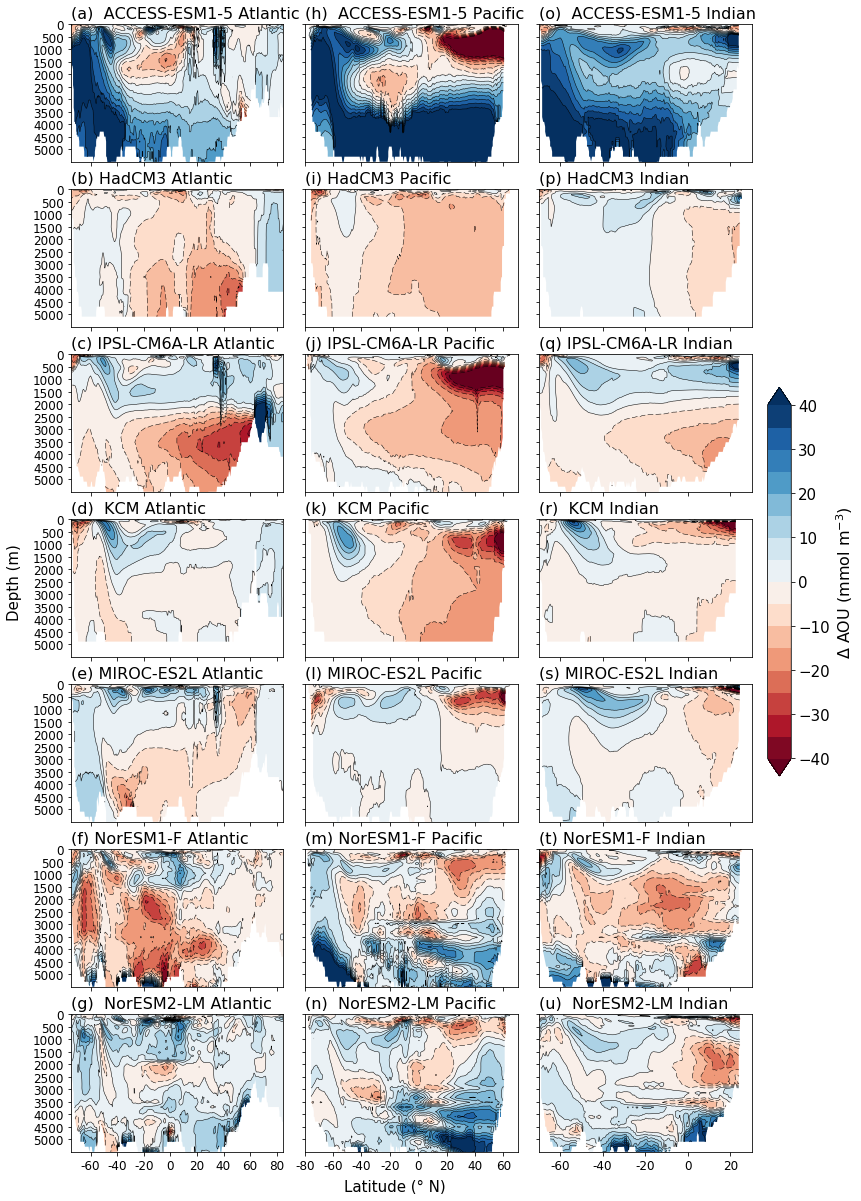

In [14]:
fig = plt.figure(figsize=(11, 18))

n_models = 7
n_basins = 3

axes = np.empty((n_models, n_basins), dtype=object)
for i in range(n_models):
    for j in range(n_basins):
        idx = i * n_basins + j + 1
        axes[i, j] = fig.add_subplot(n_models, n_basins, idx)

model_names = [' ACCESS-ESM1-5', 'HadCM3', 'IPSL-CM6A-LR', ' KCM', 'MIROC-ES2L', 'NorESM1-F', ' NorESM2-LM']
basin_names = ['Atlantic', 'Pacific', 'Indian']
simulations_list = [atl_an_zmean_aou_diff, pac_an_zmean_aou_diff, ind_an_zmean_aou_diff]
depth = ['depth', 'depth_1', 'Vertical T levels', 'plev', 'ocean sigma over z coordinate', 'depth', 'depth']

# Letters: column 1 = a-g, column 2 = h-n, column 3 = o-u
letters = list(string.ascii_lowercase)
letter_cols = [letters[0:7], letters[7:14], letters[14:21]]

levels = np.arange(-40, 40+5, 5)
levels2 = np.arange(-40, 40+5, 5)

im = None

for j, simulations in enumerate(simulations_list):
    for n in range(n_models):
        ax = axes[n, j]
        ax.set_xticks([-80, -60, -40, -20, 0, 20, 40, 60, 80])
        ax.set_xticklabels([-80, -60, -40, -20, 0, 20, 40, 60, 80])
        ax.tick_params(axis='x', labelsize=13)
        ax.tick_params(axis='y', labelsize=13)
        ax.set_ylim(0, 5500)
        
        # --- same tick positions everywhere, labels only on left column ---
        ax.set_yticks(np.arange(0, 5000+500, 500))
        if j == 0:
            ax.tick_params(axis='y', labelsize=12)
        else:
            ax.set_yticklabels([])

        if n == n_models - 1:
            ax.set_xticklabels(ax.get_xticks(), fontsize=12)
        else:
            ax.set_xticklabels([])
        #----------------------------------------------
        if j == 0:
            ax.set_xlim(-75, 85)
        elif j == 1:
            ax.set_xlim(-80, 70)
        else:
            ax.set_xlim(-70, 30)

        letter = letter_cols[j][n]
        title_str = '('+ letter + ") " + model_names[n] + " " + basin_names[j]
        ax.set_title(title_str, fontsize=16, loc='left')
        #------------------------------------------------
        im = iplt.contourf(simulations[n], coords=['latitude', depth[n]], axes=ax, levels=levels, cmap='RdBu', extend='both')
        im2 = iplt.contour(simulations[n], coords=['latitude', depth[n]], axes=ax, colors='k', levels=levels2, linewidths=0.5)

        if n in [1, 2, 3, 4, 6]:
            ax.invert_yaxis()

# shared colorbar
fig.subplots_adjust(left=0.12, right=0.88, top=0.95, bottom=0.05, wspace=0.1, hspace=0.1)
cbar_ax = fig.add_axes([0.97, 0.35, 0.03, 0.3])  # [left, bottom, width, height]
cbar = fig.colorbar(im, cax=cbar_ax)
cbar.ax.set_ylabel('Δ AOU (mmol m$^{-3}$)', size=16)
cbar.ax.tick_params(labelsize=15)

# Shared axis labels
fig.text(0.01, 0.5, 'Depth (m)', va='center', rotation='vertical', fontsize=15)
fig.text(0.5, 0.03, 'Latitude (° N)', ha='center', fontsize=15)

plt.subplots_adjust(left=0.09, bottom=0.06, right=0.95, top=0.93, wspace=0.1, hspace=0.2)
#plt.savefig('/nfs/see-fs-01_users/mlzp121/Test_HadCM3_simulations/AOU_zonally_mean_diff_3basins_v2.png', bbox_inches='tight', dpi=300, format='png')
plt.show()

### MMM

In [25]:
MMM_diff_atl = sum([atl_an_zmean_aou_diff[i].data for i in range(np.size(atl_an_zmean_aou_diff))])/7
MMM_diff_pac = sum([pac_an_zmean_aou_diff[i].data for i in range(np.size(pac_an_zmean_aou_diff))])/7
MMM_diff_ind = sum([ind_an_zmean_aou_diff[i].data for i in range(np.size(ind_an_zmean_aou_diff))])/7
## Convert arrays to iris cubes
MMM_diff_atl_cube = atl_an_zmean_aou_diff[0].copy(data = MMM_diff_atl)
MMM_diff_pac_cube = pac_an_zmean_aou_diff[0].copy(data = MMM_diff_pac)
MMM_diff_ind_cube = ind_an_zmean_aou_diff[0].copy(data = MMM_diff_ind)

#### Spread

In [26]:
def calculate_spread(dif_list, threshold=0, min_models=5):
    "Spread of the difference, where min_models agree on change above or below a threshold"
    # Model differences in a 3D array (models, lat, depth)
    model_difs = np.array([dif_list[i].data for i in np.arange(np.size(atl_an_zmean_aou_diff))])

    # Count models exceeding thresholds
    positive_count = np.sum(model_difs > threshold, axis=0)
    negative_count = np.sum(model_difs < -threshold, axis=0)

    # Agreement mask
    agreement_mask = (positive_count >= min_models) | (negative_count >= min_models)

    # Non-agreement mask
    non_agreement_mask = ~agreement_mask

    return agreement_mask, non_agreement_mask

In [27]:
agreement_atl_thresh, non_agreement_atl_thresh = calculate_spread(atl_an_zmean_aou_diff, threshold=0, min_models=5)
agreement_ind_thresh, non_agreement_ind_thresh = calculate_spread(ind_an_zmean_aou_diff, threshold=0, min_models=5)
agreement_pac_thresh, non_agreement_pac_thresh = calculate_spread(pac_an_zmean_aou_diff, threshold=0, min_models=5)

#### Plot

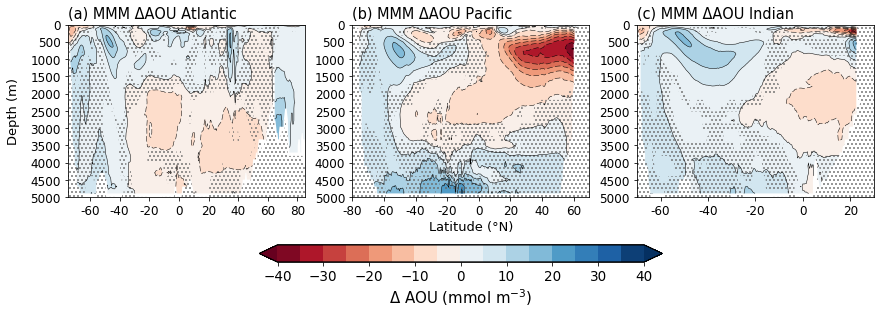

In [32]:
fig = plt.figure(figsize=(14, 3))

axes = []
for i in range(1,3+1):
    ax = fig.add_subplot(1, 3, i)
    axes.append(ax)
    
titles = ['(a) MMM ΔAOU Atlantic', '(b) MMM ΔAOU Pacific', '(c) MMM ΔAOU Indian']
depth = ['depth']*3

simulations = [MMM_diff_atl_cube, MMM_diff_pac_cube, MMM_diff_ind_cube]

for (ax, t, n) in zip(axes, titles, range(np.size(simulations))):
    ax.set_xticks([-80, -60, -40, -20, 0, 20, 40, 60, 80])
    ax.set_xticklabels([-80, -60, -40, -20, 0, 20, 40, 60, 80])
    ax.set_yticks(np.arange(0, 5000+500, 500))
    ax.tick_params(axis='x', labelsize=12)
    ax.tick_params(axis='y', labelsize=12)
    ax.set_ylim(0, 5000)
    
    if n == 2 or n == 5: ## Indian
        ax.set_xlim(-70, 30)
    elif n == 1 or n == 4: ## Pacific
        ax.set_xlim(-80, 70)
    else: ## Atlantic
        ax.set_xlim(-75, 85)
        
    ax.set_title(t, fontsize=14.5, loc='left')
       
    im = iplt.contourf(simulations[n], axes = ax, levels = np.arange(-40, 40+5, 5), cmap = 'RdBu', extend = 'both')
    im2 = iplt.contour(simulations[n], axes = ax, colors='k', levels = np.arange(-40, 40+5, 5), linewidths=0.5)

    # Hatching
    mpl.rcParams['hatch.color'] = 'dimgray'
    if n == 0:
        ax.contourf(MMM_diff_atl_cube.coord('latitude').points, MMM_diff_atl_cube.coord('depth').points,
                    non_agreement_atl_thresh, levels=[0.5, 1.5], hatches=['...'], alpha=0, colors='none')
    elif n == 1:
        ax.contourf(MMM_diff_pac_cube.coord('latitude').points, MMM_diff_pac_cube.coord('depth').points,
                    non_agreement_pac_thresh, levels=[0.5, 1.5], hatches=['...'], alpha=0, colors='none')
    else:
        ax.contourf(MMM_diff_ind_cube.coord('latitude').points, MMM_diff_ind_cube.coord('depth').points,
                    non_agreement_ind_thresh, levels=[0.5, 1.5], hatches=['...'], alpha=0, colors='none')
    # Colorbar
    cbar_ax = fig.add_axes([0.29, -0.2, 0.4, 0.08])# [left, bottom, width, height]
    cbar = fig.colorbar(im, cax=cbar_ax, orientation='horizontal')
    cbar.set_label('Δ AOU (mmol m$^{-3}$)', size=15)
    cbar.ax.tick_params(labelsize=13.5)

fig.text(0.04, 0.5, 'Depth (m)', va='center', rotation='vertical', fontsize=13)
fig.text(0.5, -0.055, 'Latitude (°N)', ha='center', fontsize=13)
plt.subplots_adjust(left=0.1,bottom=0.1,right=0.9,top=0.9,wspace=0.2,hspace=0.4)    
#plt.savefig('/nfs/see-fs-01_users/mlzp121/Test_HadCM3_simulations/AOU_MMM_diff_thresh_n_agr_vpaper_v2.png', bbox_inches='tight', dpi=300, format='png')
plt.show()